# Diversificación de portafolios con Monte Carlo (versión introductoria - sin correlaciones)

Se construyen tres portafolios con los mismos cuatro activos y distintos pesos, y se simula su valor dentro de un año.

**Activos:**

| Activo | Empresa | Moneda |
|---|---|---|
| NVDA | Nvidia | USD |
| BIMBOA.MX | Grupo Bimbo | MXN |
| CEMEXCPO.MX | Cemex | MXN |
| AZN | AstraZeneca | USD |

**Portafolios:**

| Portafolio | Pesos $w$ |
|---|---|
| P1 | [1, 0, 0, 0] |
| P2 | [0.25, 0.25, 0.25, 0.25] |
| P3 | [0.1, 0.2, 0.3, 0.4] |

**Valor inicial:** $V_0 = 100{,}000$ MXN

Como dos activos cotizan en dólares, también se simula el tipo de cambio $X$ (pesos por dólar) para expresar todo en pesos.

**Procedimiento:**
1. Descargar los precios de los últimos 3 años.
2. Estimar $\mu$ y $\sigma$ con rendimientos logarítmicos.
3. Simular el precio de cada activo y el tipo de cambio a un año ($T = 1$, $M = 10{,}000$).
4. Calcular las acciones de cada activo: $N_i = \dfrac{w_i V_0}{S_{0,i}}$
5. Calcular el valor final del portafolio: $V_T = \sum_i N_i\, S_{T,i}$

En esta versión cada activo se simula de forma independiente.

### Librerías

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

## 1. Datos históricos

### Activos y tipo de cambio

In [2]:
activos = {
    "NVDA":        "USD",
    "BIMBOA.MX":   "MXN",
    "CEMEXCPO.MX": "MXN",
    "AZN":         "USD",
}

tickers = list(activos.keys())
fx      = "MXN=X"            # pesos por dólar
todos   = tickers + [fx]

### Descarga de precios de los últimos 3 años

In [3]:
data = yf.download(todos, start="2023-11-01", end="2026-11-01",
                   auto_adjust=True, progress=False)

precios = data["Close"][todos].dropna()
print(f"Observaciones: {len(precios)}")
precios.tail()

Observaciones: 727


Ticker,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
Date,,,,,
2026-10-26,216.000000,63.490002,18.990000,172.059998,18.71900
2026-10-27,217.940002,64.849998,19.730000,170.080002,18.55020
2026-10-28,215.380005,61.830002,19.700001,169.509995,18.68704
2026-10-29,213.660004,63.689999,20.480000,174.399994,18.63179
2026-10-30,204.639999,66.180000,20.230000,186.649994,18.85210


## 2. Estimación de μ y σ

### Parámetros anualizados

In [4]:
log_ret = np.log(precios / precios.shift(1)).dropna()

sigma = log_ret.std() * np.sqrt(252)
mu    = log_ret.mean() * 252 + 0.5 * sigma**2
S0    = precios.iloc[-1]

pd.DataFrame({"S0": S0, "mu": mu, "sigma": sigma}).round(4)

,S0,mu,sigma
Ticker,,,
NVDA,204.6400,0.6603,0.4738
BIMBOA.MX,66.1800,0.0144,0.2995
CEMEXCPO.MX,20.2300,0.2747,0.3317
AZN,186.6500,0.1822,0.2518
MXN=X,18.8521,0.0214,0.1114


## 3. Simulación a un año

Como solo interesa el valor final, cada precio se simula directo a $T = 1$:

$$S_T = S_0 \exp\left[\left(\mu - \tfrac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\,Z\right]$$

### Parámetros de simulación

In [5]:
V0 = 100_000
T  = 1
M  = 10_000

### Simulación de precios finales y tipo de cambio

In [6]:
np.random.seed(42)

ST = {}
for activo in todos:
    Z = np.random.normal(0, 1, M)
    ST[activo] = S0[activo] * np.exp((mu[activo] - 0.5*sigma[activo]**2)*T
                                     + sigma[activo]*np.sqrt(T)*Z)

ST = pd.DataFrame(ST)
ST.describe().round(2)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN,MXN=X
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,395.97,67.42,26.49,223.58,19.27
std,199.82,20.69,8.94,57.42,2.15
min,55.20,20.23,7.50,70.49,11.86
25%,257.40,52.65,19.98,182.15,17.77
50%,353.56,64.50,25.15,216.39,19.16
75%,486.49,79.02,31.41,257.41,20.66
max,2274.14,245.50,85.75,554.61,28.39


### Precios en pesos

Los activos en dólares se multiplican por el tipo de cambio: el de hoy para el precio inicial y el simulado de cada escenario para el precio final.

In [7]:
X0 = S0[fx]
XT = ST[fx]

S0_mxn = {}
ST_mxn = {}
for activo in tickers:
    if activos[activo] == "USD":
        S0_mxn[activo] = S0[activo] * X0
        ST_mxn[activo] = ST[activo] * XT
    else:
        S0_mxn[activo] = S0[activo]
        ST_mxn[activo] = ST[activo]

S0_mxn = pd.Series(S0_mxn)
ST_mxn = pd.DataFrame(ST_mxn)

print(f"Tipo de cambio hoy        : {X0:.4f}")
print(f"Tipo de cambio esperado   : {XT.mean():.4f}")
print()
print("Precio inicial en pesos:")
print(S0_mxn.round(2))

Tipo de cambio hoy        : 18.8521
Tipo de cambio esperado   : 19.2731

Precio inicial en pesos:
NVDA           3857.89
BIMBOA.MX        66.18
CEMEXCPO.MX      20.23
AZN            3518.74
dtype: float64


## 4. Número de acciones por activo

Solo se pueden comprar acciones enteras, así que se redondea hacia abajo:

$$N_i = \left\lfloor \frac{w_i \, V_0}{S_{0,i}} \right\rfloor$$

El dinero que no alcanza para una acción más se queda como **efectivo**:

$$\text{Efectivo} = V_0 - \sum_i N_i \, S_{0,i}$$

### Acciones entras de cada portafolio

In [9]:
portafolios = {
    "P1": np.array([1, 0, 0, 0]),
    "P2": np.array([0.25, 0.25, 0.25, 0.25]),
    "P3": np.array([0.1, 0.2, 0.3, 0.4]),
}

acciones = {}
efectivo = {}
for nombre, w in portafolios.items():
    N = np.floor(w * V0 / S0_mxn.values)
    acciones[nombre] = N
    efectivo[nombre] = V0 - np.sum(N * S0_mxn.values)

pd.DataFrame(acciones, index=tickers).T.astype(int)

,NVDA,BIMBOA.MX,CEMEXCPO.MX,AZN
P1,25,0,0,0
P2,6,377,1235,7
P3,2,302,1482,11


### Inversión real, efectivo y pesos efectivos

Al redondear, los pesos reales del portafolio ya no son exactamente los planeados.

In [10]:
filas = []
for nombre, N in acciones.items():
    invertido = N * S0_mxn.values
    fila = {"Portafolio": nombre,
            "Invertido": invertido.sum(),
            "Efectivo": efectivo[nombre]}
    for activo, monto in zip(tickers, invertido):
        fila[f"Peso real {activo} (%)"] = monto / V0 * 100
    filas.append(fila)

pd.DataFrame(filas).round(2)

,Portafolio,Invertido,Efectivo,Peso real NVDA (%),Peso real BIMBOA.MX (%),Peso real CEMEXCPO.MX (%),Peso real AZN (%)
0,P1,96447.35,3552.65,96.45,0.00,0.00,0.00
1,P2,97712.48,2287.52,23.15,24.95,24.98,24.63
2,P3,96389.20,3610.80,7.72,19.99,29.98,38.71


## 5. Valor final del portafolio

$$V_T = \sum_{i=1}^{4} N_i \, S_{T,i} + \text{Efectivo}$$

### Valor final en cada escenario

In [11]:
VT = {}
for nombre, N in acciones.items():
    VT[nombre] = (ST_mxn.values * N).sum(axis=1) + efectivo[nombre]

### Resultados

In [12]:
resumen = []
for nombre, vt in VT.items():
    rend = vt / V0 - 1
    resumen.append({
        "Portafolio": nombre,
        "Pesos": portafolios[nombre],
        "E[V_T]": vt.mean(),
        "Rend. esperado (%)": rend.mean() * 100,
        "Volatilidad (%)": rend.std(ddof=1) * 100,
        "P(pérdida) (%)": (vt < V0).mean() * 100,
    })

pd.DataFrame(resumen).round(2)

,Portafolio,Pesos,E[V_T],Rend. esperado (%),Volatilidad (%),P(pérdida) (%)
0,P1,"[1, 0, 0, 0]",194260.22,94.26,98.86,12.35
1,P2,"[0.25, 0.25, 0.25, 0.25]",136361.30,36.36,29.35,7.37
2,P3,"[0.1, 0.2, 0.3, 0.4]",125899.08,25.90,21.96,10.82


### Distribución del valor final

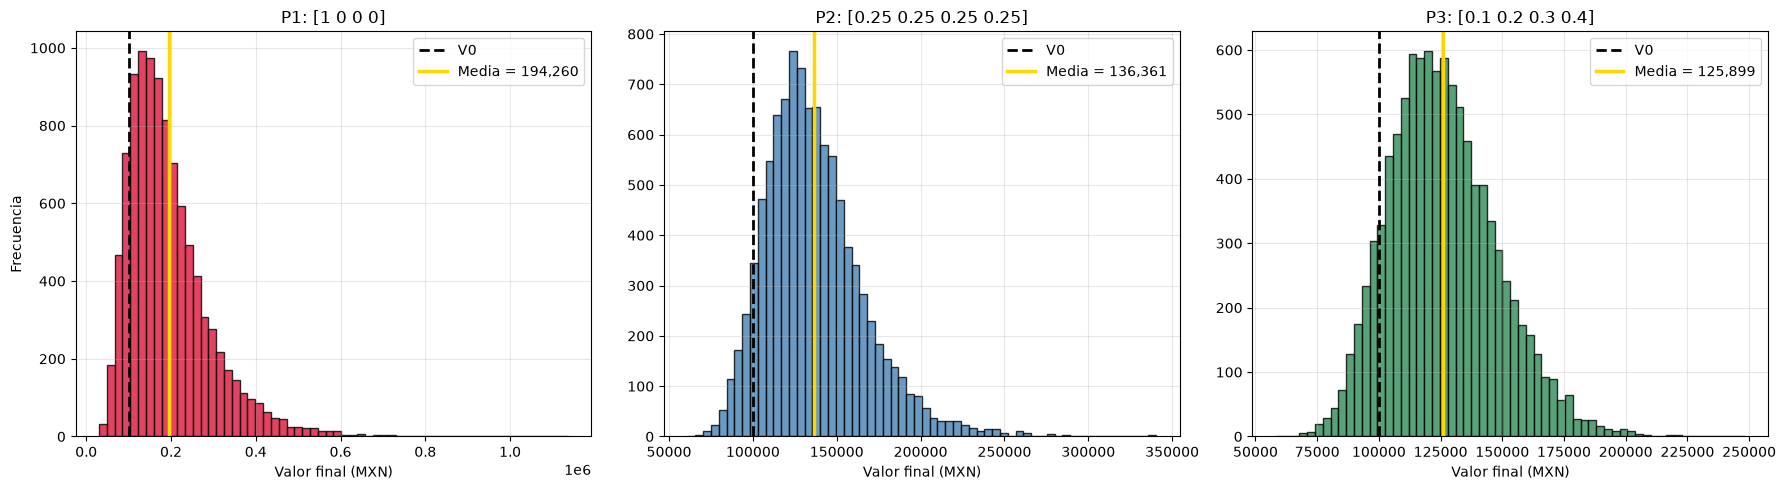

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colores = ["crimson", "steelblue", "seagreen"]

for ax, (nombre, vt), color in zip(axes, VT.items(), colores):
    ax.hist(vt, bins=60, color=color, edgecolor="black", alpha=0.8)
    ax.axvline(V0, color="black", ls="--", lw=2, label="V0")
    ax.axvline(vt.mean(), color="gold", lw=2.5, label=f"Media = {vt.mean():,.0f}")
    ax.set_title(f"{nombre}: {portafolios[nombre]}")
    ax.set_xlabel("Valor final (MXN)")
    ax.legend(); ax.grid(alpha=0.3)

axes[0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()

---

# Conclusiones

**Diversificar reduce el riesgo de forma dramática.** P1, todo en NVDA, tiene una volatilidad cercana a 100%: el valor final puede ir de una pérdida considerable a más que triplicarse. Al repartir la inversión en cuatro activos, la volatilidad baja a 29.5% en P2 y a 21.9% en P3. El riesgo se reduce a menos de un tercio.

**El rendimiento esperado no se diversifica, se promedia.** P1 tiene el rendimiento esperado más alto (94.7%) porque NVDA tuvo un desempeño extraordinario en los últimos 3 años y su μ estimado es de 66%. P2 y P3 rinden menos porque combinan a NVDA con activos de menor rendimiento, como Bimbo, cuyo μ es casi cero. El rendimiento del portafolio es el promedio ponderado de los rendimientos individuales: diversificar no lo aumenta.

**Lo que sí mejora es el riesgo por unidad de rendimiento.** P1 rinde 94.7% con 99.6% de volatilidad: un punto de riesgo por cada punto de rendimiento. P2 rinde 36.5% con 29.5% de volatilidad, una mejor relación. Aunque gana menos en promedio, sus resultados son mucho más predecibles.

**La probabilidad de perder es menor en P2 que en P1**, 7.3% contra 12.6%, a pesar de que P1 tiene un rendimiento esperado mucho mayor. P1 depende por completo de un solo activo muy volátil, y si NVDA cae, no hay nada que compense la pérdida.

**P3 es el más conservador**, con menor rendimiento y menor volatilidad, porque reduce el peso de NVDA y le da 40% a AZN, el activo menos volátil de los cuatro. Su probabilidad de pérdida es mayor que la de P2 porque su rendimiento esperado también es menor: hay menos colchón para absorber las caídas.

**Efecto de comprar acciones enteras.** Al no poder comprar fracciones, entre 2,300 y 3,600 pesos de cada portafolio se quedan en efectivo, y los pesos reales se alejan de los planeados. En P3, NVDA queda con 7.7% en lugar de 10%. Ese efectivo no tiene riesgo, pero tampoco rendimiento, y por eso los tres portafolios rinden un poco menos que con fracciones. El efecto es mayor con activos caros como NVDA y AZN, que cuestan más de 3,500 pesos por acción.

**Una advertencia sobre los parámetros.** El μ de NVDA (66%) refleja un periodo excepcional de 3 años y no es una expectativa realista a futuro. Por eso P1 parece tan atractivo en rendimiento. Con un μ más moderado, la ventaja de diversificar sería todavía más evidente.